# Модель оценки рисков задержки доставки 

**Заказчик**
- междунароная компания CargaPronto - крупнейший логистический оператор

**Цель**
- разработать систему поддержки принятия решений для логистов CargaPronto

**Бизнес-требования**
- В момент оформления заказа система должна в реальном времени оценивать риск задержки и выдавать рекомендацию о смене приоритета доставки, если риск задержки высокий

**ML постановка.**

- тип: обучение с учителем
- подтип: бинарная классификация

**Инструменты**

- Логистическая регрессия. Она ценится в бизнесе за высокую скорость и прозрачность, позволяет оценить «нижнюю планку» качества до применения сложных алгоритмов.
- Модель градиентного бустинга CatBoost, способная находить сложные закономерности в данных.

**Метрика**
- ROC-AUC
- требования по метрике: ROC-AUC > 0.75.



##  Импорт библиотек, выполнение базовых настроек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from typing import Optional
import plotly.express as px
import shap

from phik import phik_matrix
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, TargetEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_curve, auc, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from catboost import CatBoostClassifier
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

In [2]:
# воспроизводимость  вычислений
RANDOM_SEED = 42 

In [3]:
# настройка визуалиции 
plt.rcParams["figure.figsize"] = (12, 8)
pd.set_option('display.max_colwidth', None)

## Загрузка данных, первичный анализ

In [4]:
df_customers = pd.read_csv("https://code.s3.yandex.net/datasets/ds_s18_customers.csv")
df_orders = pd.read_csv("https://code.s3.yandex.net/datasets/ds_s18_orders.csv")

In [5]:
display(df_customers.info(), df_orders.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20652 entries, 0 to 20651
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   20652 non-null  int64  
 1   customer_lat  20652 non-null  float64
 2   customer_lon  20652 non-null  float64
 3   total_sales   20652 non-null  float64
 4   total_orders  20652 non-null  int64  
 5   avg_discount  20652 non-null  float64
 6   return_rate   20652 non-null  float64
 7   recency       20652 non-null  int64  
dtypes: float64(5), int64(3)
memory usage: 1.3 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            180519 non-null  int64  
 1   customer_id         180519 non-null  int64  
 2   late_delivery_risk  180519 non-null  int64  
 3   shipping_mode       180519 non-null  object 
 4

None

None

In [6]:
# определение категориальных и числовых типов
CAT_COLS_TYPES = ['object', 'category']
NUM_COLS_TYPES = [np.number]

def get_cat_num_cols(df: pd.DataFrame) -> tuple[list[str], list[str]]:
    """Получить списки названий категориальных и числовых столбцов"""
    cat_cols = df.select_dtypes(include=CAT_COLS_TYPES).columns.tolist()
    num_cols = df.select_dtypes(include=NUM_COLS_TYPES).columns.tolist()

    return cat_cols, num_cols

def get_base_df_info(name: str, df: pd.DataFrame):
    """Информация о датафрейме для ИАД анализа"""
    
    rows_count, cols_count = df.shape
    missing = df.isna().sum()
    missing_share = (missing / rows_count * 100).round(2) if rows_count else pd.Series(0, index=df.columns, dtype=float)
    duplicates_count = (df.duplicated().sum() / rows_count * 100).round(2)
    unique_values = df.nunique(dropna=False)

    cat_cols, num_cols = get_cat_num_cols(df=df)

    overview_df = pd.DataFrame({
        'Метрика': ['Строк', 'Колонок', 'Явных дубликатов, %', 'Категориальных колонок', 'Числовых колонок'],
        'Значение': [rows_count, cols_count, duplicates_count, int(len(cat_cols)), int(len(num_cols))],
    })

    summary_df = pd.DataFrame({
        'Тип данных': df.dtypes.astype(str),
        'Пропуски': missing,
        'Доля пропусков, %': missing_share,
        'Уникальные значения': unique_values,
    }).sort_values(by=['Пропуски', 'Уникальные значения'], ascending=[False, False])

    cols_df = pd.DataFrame({
        'Категориальные колонки': pd.Series(cat_cols),
        'Числовые колонки': pd.Series(num_cols),
    })

    print(f'Общая информация о датафрейме {name}')
    display(df.head())
    display(overview_df)

    print('Сводка по признакам')
    display(summary_df)

    print('Типы колонок')
    display(cols_df)
    print('-'*50)

In [7]:
get_base_df_info(name='customers', df=df_customers)

Общая информация о датафрейме customers


,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
0,1,25.953648,-97.507683,472.450012,1,0.060,0.0,793
1,2,38.375595,-104.726021,1618.660042,4,0.126,0.0,137
2,3,18.025375,-66.615082,3189.200037,5,0.105,0.0,230
3,4,33.670021,-112.247078,1480.709993,4,0.135,0.0,381
4,5,18.359104,-66.077911,1101.919998,3,0.140,0.0,458


,Метрика,Значение
0,Строк,20652.0
1,Колонок,8.0
2,"Явных дубликатов, %",0.0
3,Категориальных колонок,0.0
4,Числовых колонок,8.0


Сводка по признакам


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
customer_id,int64,0,0.0,20652
customer_lat,float64,0,0.0,12767
total_sales,float64,0,0.0,12632
avg_discount,float64,0,0.0,10600
customer_lon,float64,0,0.0,6161
recency,int64,0,0.0,1012
return_rate,float64,0,0.0,166
total_orders,int64,0,0.0,15


Типы колонок


,Категориальные колонки,Числовые колонки
0,NaN,customer_id
1,NaN,customer_lat
2,NaN,customer_lon
3,NaN,total_sales
4,NaN,total_orders
5,NaN,avg_discount
6,NaN,return_rate
7,NaN,recency


--------------------------------------------------


In [8]:
get_base_df_info(name='orders', df=df_orders)

Общая информация о датафрейме orders


,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.75
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.75
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.75
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.75
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.75


,Метрика,Значение
0,Строк,180519.0
1,Колонок,7.0
2,"Явных дубликатов, %",0.0
3,Категориальных колонок,3.0
4,Числовых колонок,4.0


Сводка по признакам


,Тип данных,Пропуски,"Доля пропусков, %",Уникальные значения
order_id,int64,0,0.0,180519
order_date,object,0,0.0,65752
customer_id,int64,0,0.0,20652
item_price,float64,0,0.0,75
category_name,object,0,0.0,50
shipping_mode,object,0,0.0,4
late_delivery_risk,int64,0,0.0,2


Типы колонок


,Категориальные колонки,Числовые колонки
0,shipping_mode,order_id
1,category_name,customer_id
2,order_date,late_delivery_risk
3,NaN,item_price


--------------------------------------------------


Анализ:
- в обоих датасетах явных дублей и пропусков нет


### Проверка консистентности ID

In [9]:
# ID согласованы между датафреймами 
sorted(df_orders['customer_id'].unique().tolist()) == df_customers['customer_id'].values.tolist()


True

In [10]:

print('Каждый заказ имеет уникальный ID: ', df_orders['order_id'].nunique() == len(df_orders))
print('Каждый клиент уникален: ', df_customers['customer_id'].nunique() == len(df_customers))

Каждый заказ имеет уникальный ID:  True
Каждый клиент уникален:  True


Анализ:
- ID клиентов в датасете заказов согласуются с ID клиентов в датасете клиентов
- ID внутри соответствующих датафреймов уникальные

### Подготовка признаков с датой и временем

In [11]:
df_orders['order_date'] = pd.to_datetime(df_orders['order_date'])

In [12]:
df_orders['order_month'] = df_orders['order_date'].dt.month
df_orders['order_weekday'] = df_orders['order_date'].dt.weekday
df_orders['order_hour'] = df_orders['order_date'].dt.hour

In [13]:
df_orders = df_orders.drop(columns='order_date')

### Приведение категориальных признаков к pd.categorical


In [14]:
cat_cols, _ = get_cat_num_cols(df_orders)

cat_cols += ['order_month', 'order_weekday', 'order_hour']

for col in cat_cols:
	# приведение всех категориальных признаков к pd.categorical
	df_orders[col] = df_orders[col].astype('category')

In [15]:
cat_cols, _ = get_cat_num_cols(df_customers)

for col in cat_cols:
	# приведение всех категориальных признаков к pd.categorical
	df_customers[col] = df_customers[col].astype('category')

## EDA

In [16]:
def plot_count_bars(
    df: pd.DataFrame, col_name: str,
    show_mean: bool = False
):
    """Столбчатые диаграммы распрелелений категориальных признаков"""
    counts = df[col_name].value_counts()
    freq_order = counts.index
    mean_value = counts.mean()

    ax = sns.countplot(data=df, x=col_name, order=freq_order)

    if show_mean:
        # горизонтальная линия среднего значения
        plt.axhline(
            y=mean_value,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Среднее: {mean_value:.1f}",
        )
        plt.legend()

    plt.title(f"Распределение {col_name}")
    plt.ylabel("количество")
    plt.xticks(rotation=45)


    plt.ylim(top=plt.ylim()[1] * 1.05)

    plt.show()

In [17]:
def plot_hist_box(
    df: pd.DataFrame, 
    feature_name: str,
    x_label: str = 'значение',
    bins=30,
    hue: Optional[str]=None
):
    """Гистограмма + ящик с усами для анализа распределений количественных данных"""
    fig, axes = plt.subplots(nrows=2, ncols=1)
    axes[0].grid(True)
    axes[1].grid(True)
    sns.histplot(data=df, x=feature_name, stat='density', ax=axes[0], bins=bins, hue=hue, legend=True)
    
    plt.figtext(
        0.75,0.4, 
        df[feature_name].describe().to_string(), 
        fontsize=10,
        family="monospace",  # Ensures perfect columns alignment
        verticalalignment="center",
        bbox=dict(boxstyle="square,pad=0.6", facecolor="#f8f9fa", edgecolor="gray"),
    )

    sns.boxplot(data=df, x=feature_name, orient="h", ax=axes[1])
    axes[0].set_title(f'Распределение {feature_name}')
    axes[0].set_ylabel('плотность')
    axes[1].set_xlabel(x_label)
    axes[1].set_ylabel(feature_name)
    plt.show()

In [18]:
def show_category_parts(
    df_to_analyse: pd.DataFrame, 
    colname_groupby: str, 
    part_category: str, 
    title: str = '', 
    df_init: pd.DataFrame = None
):
    df_unstack = df_to_analyse.groupby(colname_groupby)[part_category].value_counts(normalize=True).unstack(fill_value=0)

    if True in df_unstack.columns:
        sort_col = True
    elif 1 in df_unstack.columns:
        sort_col = 1
    else:
        sort_col = df_unstack.columns[0]

    df_unstack = df_unstack.sort_values(by=sort_col, ascending=False)
    print(df_unstack)

    if df_init is not None:
        df_init_unstack = df_init.groupby(colname_groupby)[part_category].value_counts(normalize=True).unstack(fill_value=0)
        mean_share = df_init_unstack[sort_col].mean()
    else:
        mean_share = df_unstack[sort_col].mean()
    print(f'Средняя доля по "{sort_col}": {mean_share:.1%}')


    ax = df_unstack.plot(kind='bar')


    plt.title(title)
    plt.ylabel('Доля') 
    plt.xlabel('Категория') 
    plt.xticks(rotation=45)  
    plt.legend()  

    # Отображаем график
    plt.show()

### Таблица orders

In [19]:
cat_cols, num_cols = get_cat_num_cols(df=df_orders)
order_feature_cols = cat_cols + num_cols
target_name = 'late_delivery_risk'
order_feature_cols = [name for name in order_feature_cols if name != target_name]

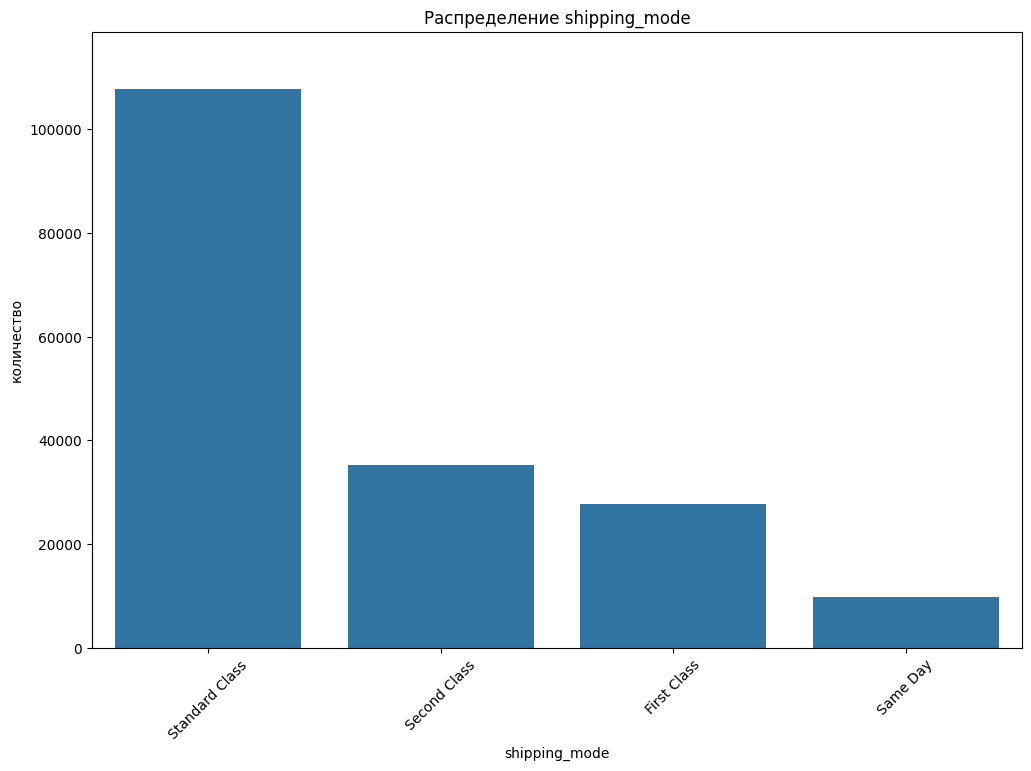

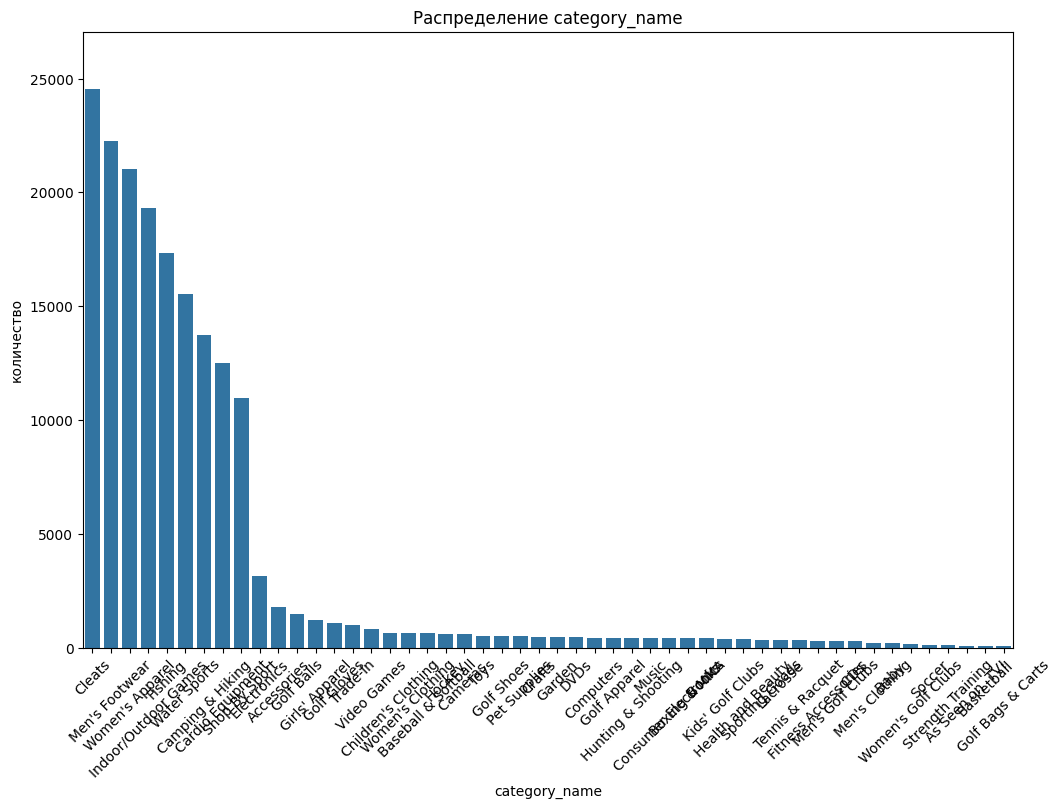

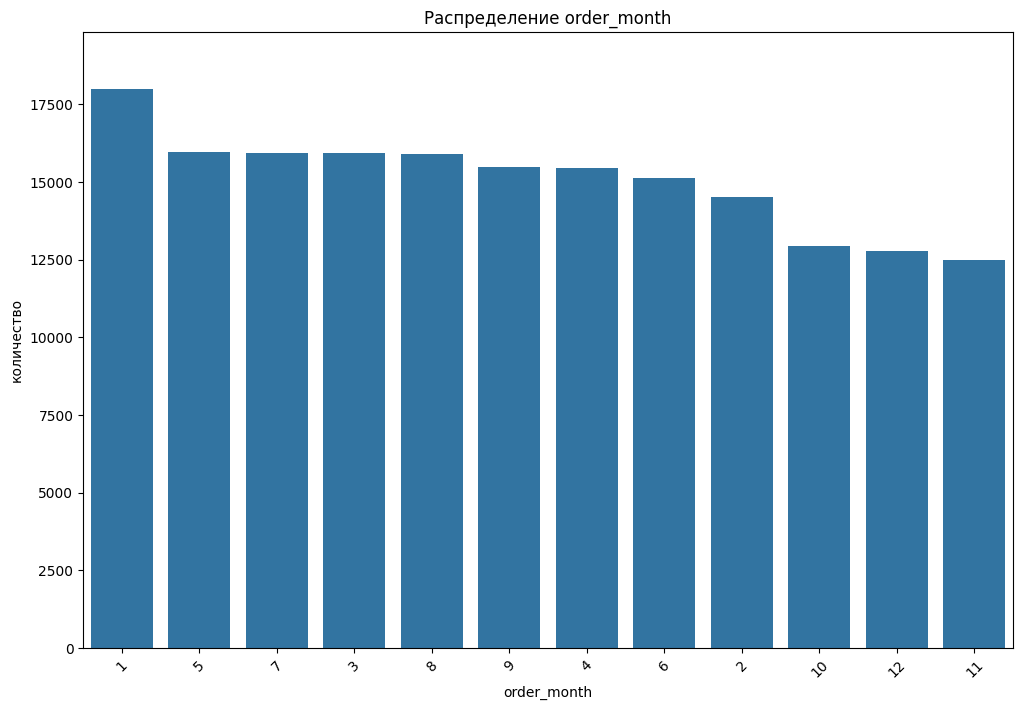

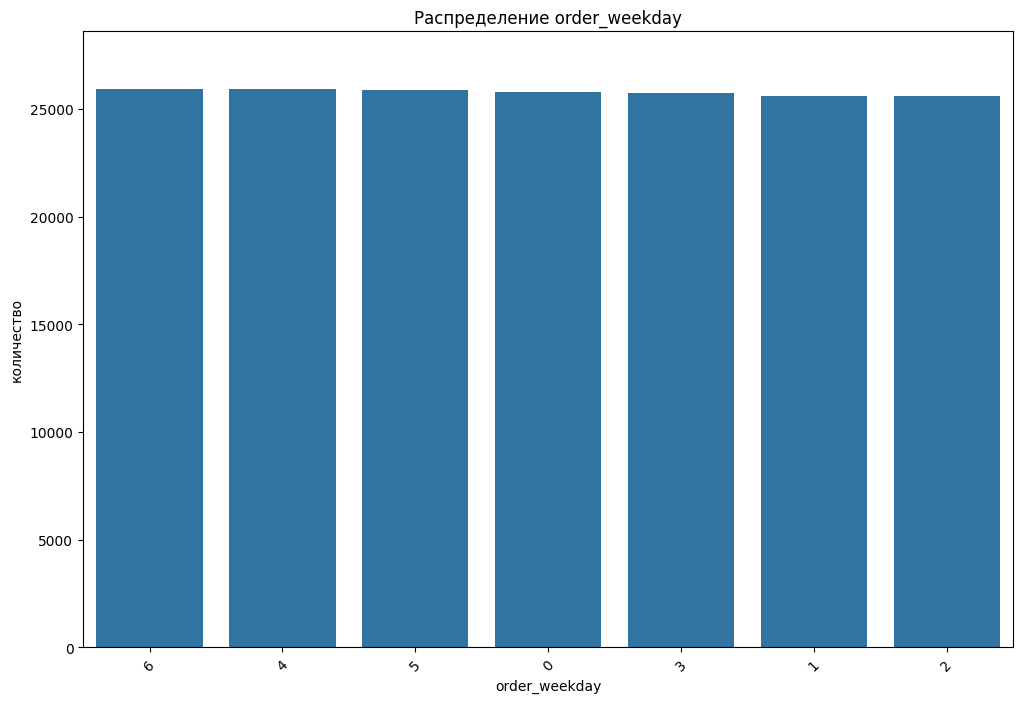

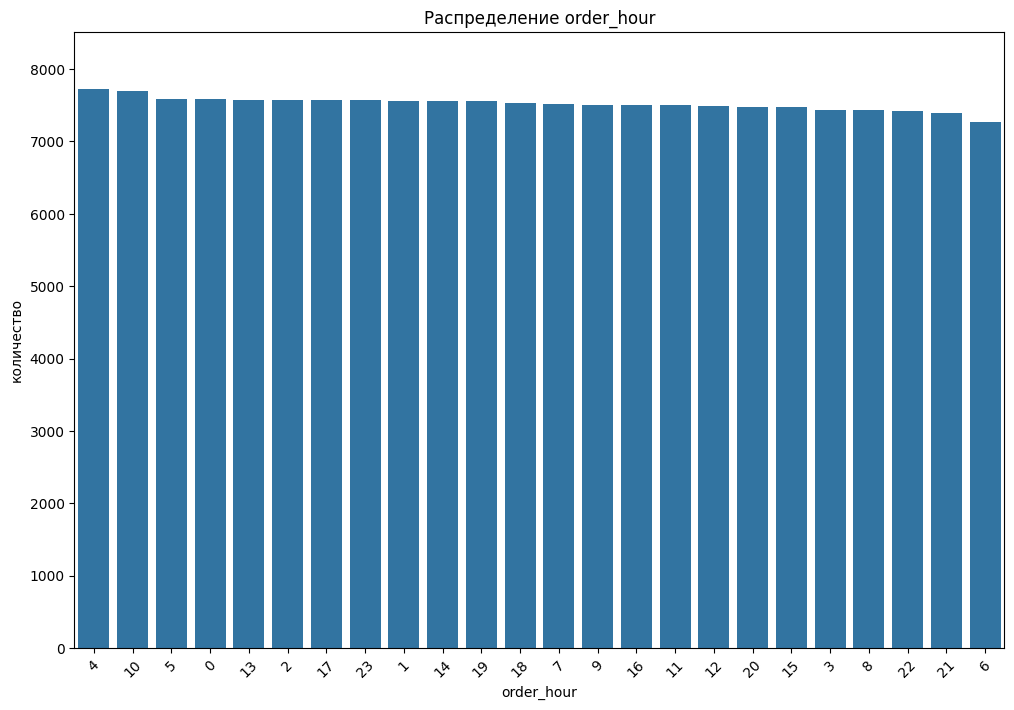

In [20]:
for name in cat_cols:
    plot_count_bars(df=df_orders, col_name=name)

Анализ:
- shipping_mode: существенно преобладает Standard Class - им чаще всего отправляют
- category_name: есть топ-9 категорий, которые существенно больше заказывают

late_delivery_risk         0         1
shipping_mode                         
First Class         0.046775  0.953225
Second Class        0.233672  0.766328
Same Day            0.542570  0.457430
Standard Class      0.619283  0.380717
Средняя доля по "1": 63.9%


/var/folders/z5/m0jnh3gs29l1r8s11wsrcwyr0000gp/T/ipykernel_89557/4148815689.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_unstack = df_to_analyse.groupby(colname_groupby)[part_category].value_counts(normalize=True).unstack(fill_value=0)


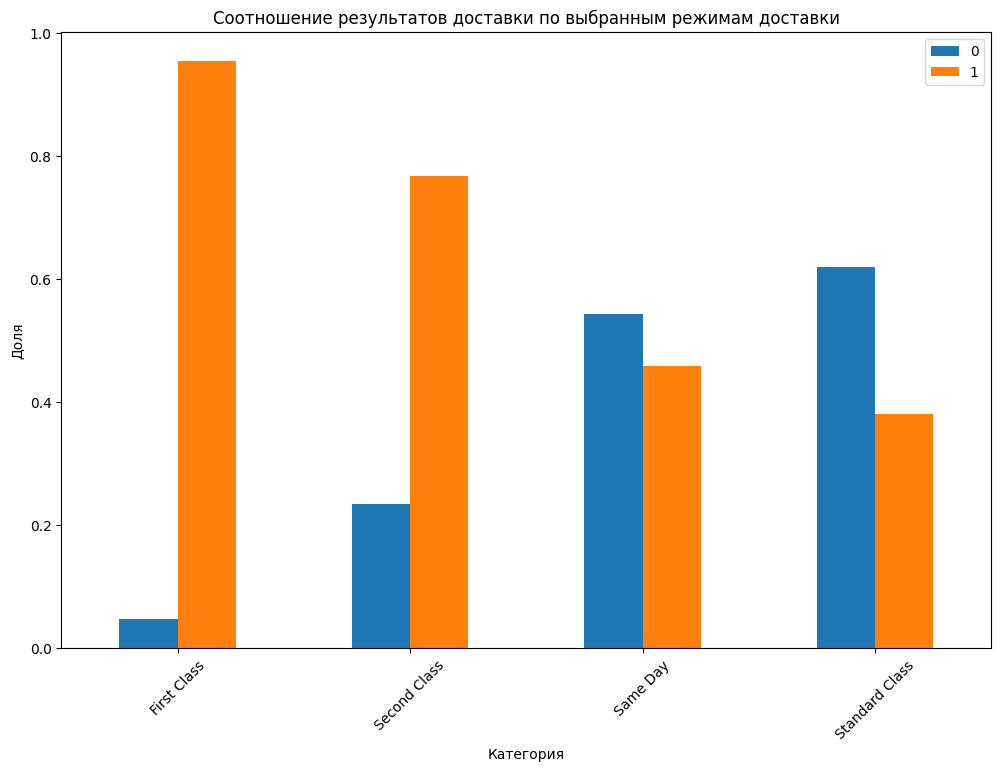

In [21]:
show_category_parts(
    df_orders, 
    colname_groupby='shipping_mode' , 
    part_category='late_delivery_risk',
    title='Соотношение результатов доставки по выбранным режимам доставки'
)

Анализ:
- категорий мало. На этапе предобработки можно воспользоваться one-hot кодированием 
- доля задержек в первом и втором режиме доставки существенно выше, чем в остальных

late_delivery_risk           0         1
category_name                           
Golf Bags & Carts     0.311475  0.688525
Lacrosse              0.399417  0.600583
Pet Supplies          0.410569  0.589431
Cameras               0.418919  0.581081
Strength Training     0.423423  0.576577
As Seen on  TV!       0.426471  0.573529
Music                 0.428571  0.571429
Accessories           0.430337  0.569663
Fitness Accessories   0.430421  0.569579
Books                 0.434568  0.565432
Women's Clothing      0.435385  0.564615
Boxing & MMA          0.437352  0.562648
Golf Gloves           0.437383  0.562617
Hunting & Shooting    0.438636  0.561364
Electronics           0.439163  0.560837
Crafts                0.440083  0.559917
Health and Beauty     0.441989  0.558011
Tennis & Racquet      0.442073  0.557927
Garden                0.442149  0.557851
Trade-In              0.443532  0.556468
Golf Shoes            0.444656  0.555344
Sporting Goods        0.445378  0.554622
Girls' Apparel  

/var/folders/z5/m0jnh3gs29l1r8s11wsrcwyr0000gp/T/ipykernel_89557/4148815689.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_unstack = df_to_analyse.groupby(colname_groupby)[part_category].value_counts(normalize=True).unstack(fill_value=0)


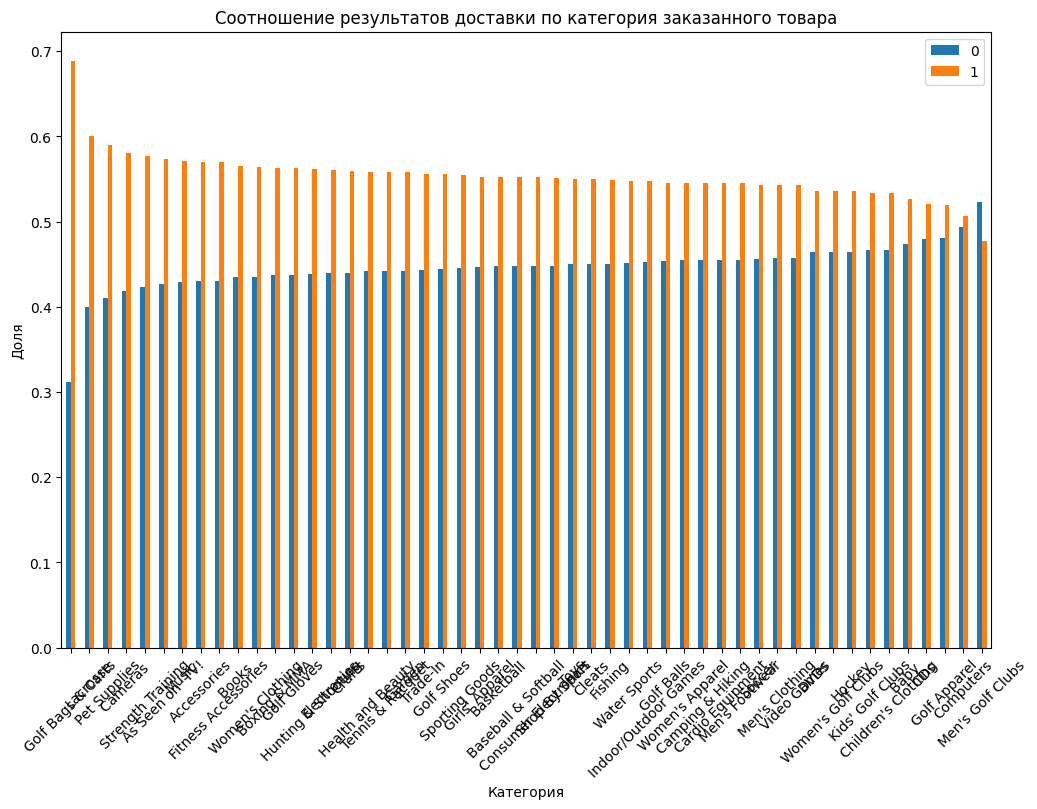

In [22]:
show_category_parts(
    df_orders, 
    colname_groupby='category_name' , 
    part_category='late_delivery_risk',
    title='Соотношение результатов доставки по категория заказанного товара'
)

Анализ:
- кол-во категорий большое (>10). Чтобы не раздувать признаковое пространство, необходимо воспользоваться TargetEncoding 
- в большинстве категорий товаров доля задержек преобладает
- в категории **Golf Bags & Carts** задержек около 68% - рекордный показатель
- в единственной категории **Men's Golf Clubs** задержек меньше, чем своевременных заказов

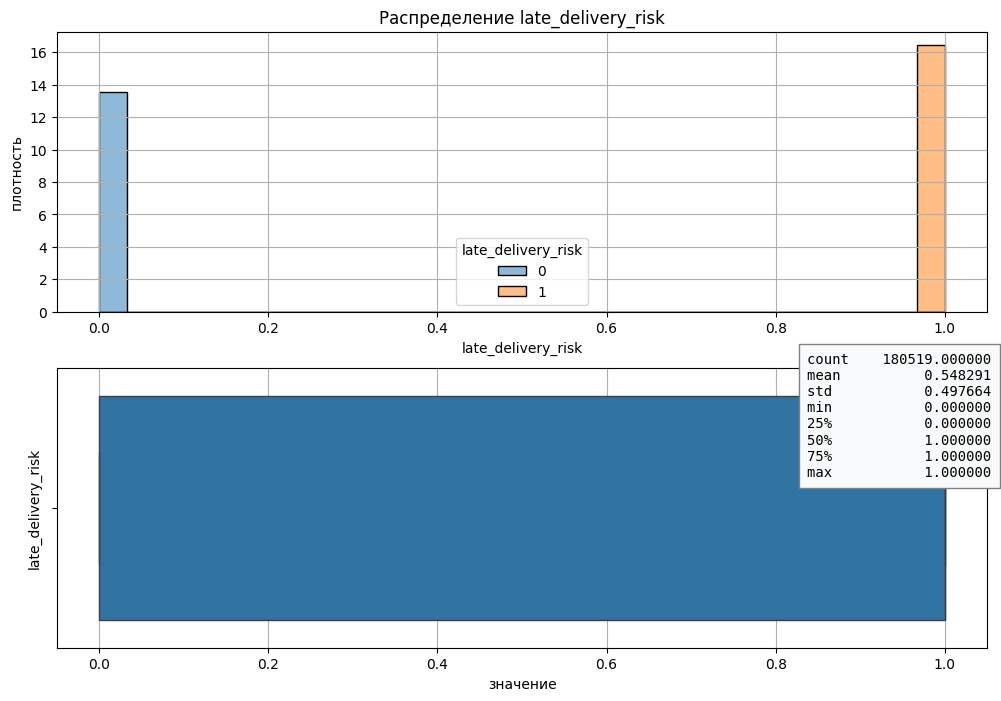

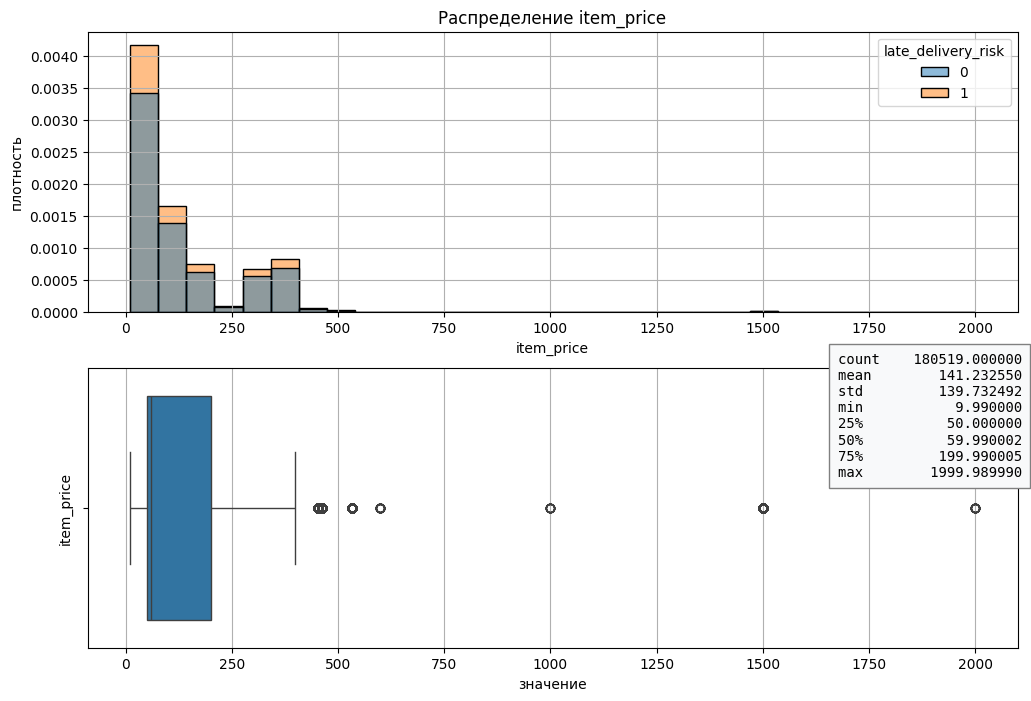

In [23]:
num_cols = [name for name in num_cols if name not in ['order_id', 'customer_id']]
for name in num_cols:
    plot_hist_box(df=df_orders, feature_name=name, hue=target_name)

Анализ:
- item_price: распределение несимметричное, есть существенные выбросы с высокой ценой. Доля задержек выше у дешевых товаров
- по временным признакам распределения близкие к равномерным. Доля отказов увеличивается с 12 до 23 часов


### Анализ целевой переменной

In [24]:
df_orders[target_name].value_counts() / len(df_orders[target_name]) * 100

late_delivery_risk
1    54.829132
0    45.170868
Name: count, dtype: float64

Анализ:
- late_delivery_risk: дисбаланс классов для тергет переменной несущественный 55/45%
- информация о 55% задержек подтверждается

### Географический аудит

In [25]:
def plot_customers_geo(df: pd.DataFrame):
    """Расположение клиентов на карте"""
    fig = px.scatter_map(
        df,
        lat='customer_lat',
        lon='customer_lon',
        hover_name=df.index,
        hover_data={
            'customer_lat': ':.4f',
            'customer_lon': ':.4f'
        },
        color_discrete_sequence=['blue'],
        zoom=1,
        height=600,
        title='Распределение клиентов по геолокации'
    )

    fig.update_layout(
        mapbox_style='open-street-map',
        mapbox_center={'lat': 0, 'lon': 0},
        margin={'r': 0, 't': 50, 'l': 0, 'b': 0}
    )

    fig.show()

In [26]:
plot_customers_geo(df=df_customers)

Анализ:
- обнаружены точки в Тихом океане, близко к Европе и в Азии

Вывод:
- поскольку известно, что компания работает с клиентами из США и Пуэрто-Рико, точки в других локациях являются шумом. Необходимо провести фильтрацию шума в данных

In [27]:
def filter_geo_data(df: pd.DataFrame, max_lat=50., min_lat=15., max_lon=-60, min_lon=-125):
    """Фильтрация геоданных по долготе и широте"""
    mask = (
        df['customer_lat'].between(min_lat, max_lat) & 
        df['customer_lon'].between(min_lon, max_lon)
    )
    return df[mask]

In [28]:
df_customers_filtered = filter_geo_data(df=df_customers)
plot_customers_geo(df=df_customers_filtered)


In [29]:
df_orders_filtered = df_orders[df_orders['customer_id'].isin(df_customers_filtered['customer_id'])]

In [30]:
# процент потерь при фильтрации
orders_loss_p = (len(df_orders) - len(df_orders_filtered)) / len(df_orders) * 100 
customers_loss_p = (len(df_customers) - len(df_customers_filtered)) / len(df_customers) * 100 
print('Потери в датасете заказов (%): ', orders_loss_p)
print('Потери в датасете клиентов (%): ', customers_loss_p)

Потери в датасете заказов (%):  0.7921603820096499
Потери в датасете клиентов (%):  0.7553747821034282


Итог:
- Проведена фильтрация выбросов по геоданным, процент потерь в каждом датасете менее 0.8%

### Корреляционный анализ

In [31]:
def get_corr_matrix(
    data: pd.DataFrame, feat_cols: list[str], 
    num_cols: list[str]
):
    """Матрица корреляций"""
    corr_matrix = data[feat_cols].phik_matrix(
        interval_cols=num_cols if len(num_cols) > 0 else None,
        njobs=-1,
    )

    return corr_matrix

def plot_corr_matrix(corr_matrix):
    """Тепловая карта"""
    plt.figure(figsize=(14, 10)) 

    sns.heatmap(data=corr_matrix, annot=True, fmt='.2f', linewidths=0.5, cmap='viridis')

    plt.title('Тепловая карта матрицы корреляций')
    plt.show()

def corr_with_target(corr_matrix, target_col_name):
    """Корреляция с таргетом"""
    return corr_matrix[target_col_name].sort_values(ascending=False)

In [32]:
corr_matrix = get_corr_matrix(
    data=df_orders, 
    feat_cols=num_cols + cat_cols, 
    num_cols=num_cols
)

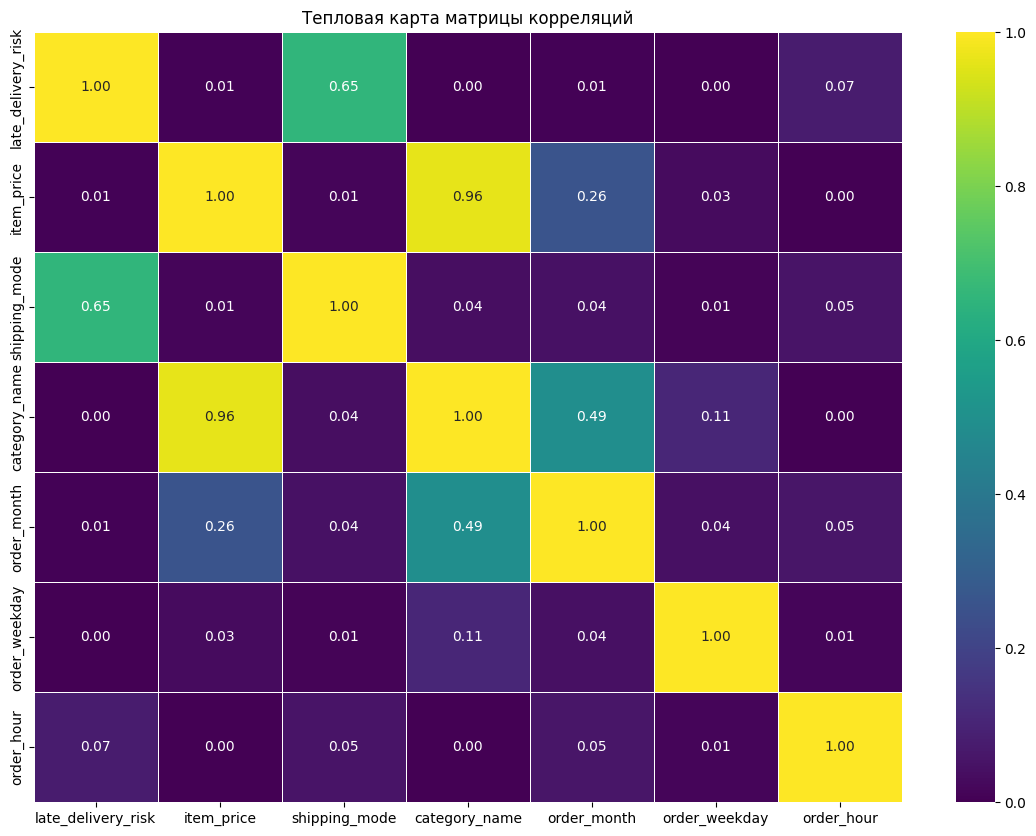

In [33]:
plot_corr_matrix(corr_matrix)

Анализ:
- категория товара сильно коррелирует с ценой: corr = 0.96. Можно предположить, что товары одной категории имеют один ценовой сегмент
- наибольшая по модулю корреляция с таргетом у shipping_mode. Похоже, что режим доставки сильнее остальных признаков связан с вероятностью задержки

### Вывод по ИАД

Таргет:
- дисбаланс классов для тергет переменной несущественный 55/45%
- подтвержилась информация о 55% просрочек

Количественные признаки:
- item_price: распределение несимметричное, есть существенные выбросы с высокой ценой. Доля задержек выше у дешевых товаров.
- по временным признакам распределения близкие к равномерным. Доля отказов увеличивается с 12 до 23 часов

Категориальные признаки:
- в большинстве категорий товаров доля задержек преобладает
- в категории **Golf Bags & Carts** задержек около 68% - рекордный показатель
- в единственной категории **Men's Golf Clubs** задержек меньше, чем своевременных заказов
- доля задержек в первом и втором режиме доставки существенно выше, чем в остальных
- shipping_mode: существенно преобладает Standard Class - им чаще всего отправляют
- category_name: есть топ-9 категорий, которые существенно больше заказывают

Географический аудит:
- выявлены выбросы по геоданным клиентов
- проведена фильтрация выбросов. Процент потерь в датасетах составил менее 0.8%

Корреляционный анализ:
- категория товара сильно коррелирует с ценой: corr = 0.96. Можно предположить, что товары одной категории имеют один ценовой сегмент
- наибольшая по модулю корреляция с таргетом у shipping_mode. Похоже, что режим доставки сильнее остальных признаков связан с вероятностью задержки

Комментарии для предобработки:
- category_name: более 10 уникальных категорий -> TargetEncoding
- shipping_mode: 4 уникальные категории -> OneHotEncoding

##  Разделение на выборки

- разбиение по группам: один и тот же клиент не должен попасть в разные выборки

In [34]:
# train_val - 80, test - 20
groups = df_orders_filtered['customer_id']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED)
train_val_idx, test_idx = next(gss.split(X=df_orders_filtered, groups=groups))

df_train_val = df_orders_filtered.iloc[train_val_idx]
df_test = df_orders_filtered.iloc[test_idx]

In [35]:
# train 60, val - 20
groups2 = df_train_val['customer_id']
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_SEED)
train_idx, val_idx = next(gss2.split(X=df_train_val, groups=groups2))

df_train = df_train_val.iloc[train_idx]
df_val = df_train_val.iloc[val_idx]

In [36]:
display(df_train.shape, df_val.shape, df_test.shape)

(107661, 9)

(35416, 9)

(36012, 9)

Проверка разбиения:
- не должно быть совпадающих id ни в одной паре 

In [37]:
train_id = df_train['customer_id'].values
val_id = df_val['customer_id'].values
test_id = df_test['customer_id'].values

id_combinations = list(combinations([train_id, val_id, test_id], 2))

for rhs, lhs in id_combinations:
    print('Повторы id: ', len(set(rhs) & set(lhs)))

Повторы id:  0
Повторы id:  0
Повторы id:  0


Итог:
- разбиение на train - 60%, validate - 20%, test - 20% проведено корректно

In [38]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 107661 entries, 1 to 180516
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype   
---  ------              --------------   -----   
 0   order_id            107661 non-null  int64   
 1   customer_id         107661 non-null  int64   
 2   late_delivery_risk  107661 non-null  int64   
 3   shipping_mode       107661 non-null  category
 4   category_name       107661 non-null  category
 5   item_price          107661 non-null  float64 
 6   order_month         107661 non-null  category
 7   order_weekday       107661 non-null  category
 8   order_hour          107661 non-null  category
dtypes: category(5), float64(1), int64(3)
memory usage: 4.6 MB


## Пайплайн предобработки данных

In [39]:
def select_cat_one_hot(X):
    """Отбор категорий для OneHot кодирования"""
    cat_cols = X.select_dtypes(include=CAT_COLS_TYPES).columns.tolist()
    return [name for name in cat_cols if X[name].nunique() < 10]

def select_cat_target(X):
    """Отбор категорий для Target кодирования"""
    cat_cols = X.select_dtypes(include=CAT_COLS_TYPES).columns.tolist()
    return [name for name in cat_cols if X[name].nunique() >= 10]

def select_num_cols_continues(X):
    """Отбор непрерывных количественных признаков"""
    num_cols =X.select_dtypes(include=['float']).columns.tolist()
    return num_cols

def select_num_cols_discrete(X):
    """Отбор дискретных количественных признаков"""
    num_cols =X.select_dtypes(include=['int']).columns.tolist()
    return num_cols

In [40]:
def create_preprocessor(
) -> ColumnTransformer:
    """
    Создание предобратботчика данных.
    """

    # Пайплайны для разных типов признаков
    cat_one_hot_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first'))
    ])
    cat_target_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', TargetEncoder())
    ])

    num_continues_cols_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])

    num_discrete_cols_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('scaler', MinMaxScaler())
    ])

    transformers = [
        ('cat_one_hot', cat_one_hot_pipeline, select_cat_one_hot),
        ('cat_target', cat_target_pipeline, select_cat_target),
        ('num_continues', num_continues_cols_pipeline, select_num_cols_continues),
        ('num_discrete', num_discrete_cols_pipeline, select_num_cols_discrete)
    ]
    
    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder='drop'
    )

    return preprocessor


## Обучение базовой модели

In [41]:
# признаки и таргет для обучения
baseline_features = ['shipping_mode', 'category_name', 'item_price', 'order_hour', 'order_weekday', 'order_month']
target_name = 'late_delivery_risk'

In [42]:
X_train = df_train[baseline_features]
y_train = pd.Series(data=df_train[target_name].values, name='target')

X_val = df_val[baseline_features]
y_val = pd.Series(data=df_val[target_name].values, name='target')

display(X_train.head(), y_train.head())

,shipping_mode,category_name,item_price,order_hour,order_weekday,order_month
1,Standard Class,Sporting Goods,327.75,12,5,1
2,Standard Class,Sporting Goods,327.75,12,5,1
5,Standard Class,Sporting Goods,327.75,11,5,1
7,First Class,Sporting Goods,327.75,10,5,1
10,Second Class,Sporting Goods,327.75,9,5,1


0    1
1    0
2    0
3    1
4    0
Name: target, dtype: int64

In [43]:
def evaluate_model(y_true_binary, y_pred_probas, name: str):
    """Оценка качества модели по ключевым метрикам"""
    roc_auc_metric = roc_auc_score(y_true=y_true_binary, y_score=y_pred_probas)

    return pd.DataFrame(
        {
            'name': [name],
            'roc_auc_score': [roc_auc_metric],
        }
    )

In [44]:
def plot_auc_roc_curve(y_true, y_probas: list[pd.Series], labels: list[str]):
    
    for model, y_proba in zip(labels, y_probas):
        fpr, tpr, _ = roc_curve(y_true, y_proba)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{model} (ROC-AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'r--', label='Случайный классификатор')

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC кривая')
    plt.grid()
    plt.legend()
    plt.show()


### Обучение логистической регрессии

In [45]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 107661 entries, 1 to 180516
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype   
---  ------         --------------   -----   
 0   shipping_mode  107661 non-null  category
 1   category_name  107661 non-null  category
 2   item_price     107661 non-null  float64 
 3   order_hour     107661 non-null  category
 4   order_weekday  107661 non-null  category
 5   order_month    107661 non-null  category
dtypes: category(5), float64(1)
memory usage: 2.2 MB


In [46]:
baseline_logreg_model = LogisticRegression(
    random_state=RANDOM_SEED, class_weight="balanced",
    max_iter=1000, penalty='elasticnet', solver='saga', l1_ratio=0.5
)

baseline_logreg_pipeline = Pipeline(
    steps=[
        ('preproc', create_preprocessor()),
        ('model', baseline_logreg_model)
    ]
)

baseline_logreg_pipeline.fit(X_train, y_train)

# проверка на валидационной выборке
y_logreg_val_pred = baseline_logreg_pipeline.predict(X_val)
y_proba_logreg_val_pred = baseline_logreg_pipeline.predict_proba(X_val)[:, 1]

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encoun

### Обучение CatBoostClassifier

In [47]:
cat_cols, _ = get_cat_num_cols(X_train)
cat_cols

['shipping_mode',
 'category_name',
 'order_hour',
 'order_weekday',
 'order_month']

In [48]:
cbc_model_base = CatBoostClassifier(
    random_state=RANDOM_SEED,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=50,
    use_best_model=True,
    verbose=False,
    n_estimators=1500,
    cat_features=cat_cols
)

In [49]:
cbc_model_base.fit(
    X_train, y_train,
    cat_features=cat_cols,
    eval_set=(X_val, y_val),
    verbose=False,
    use_best_model=True
)

CatBoostClassifier(cat_features=['shipping_mode', 'category_name', 'order_hour', 'order_weekday', 'order_month'], early_stopping_rounds=50, eval_metric='AUC', loss_function='Logloss', n_estimators=1500, random_state=42, use_best_model=True, verbose=False)

In [50]:
# предсказания на validate
y_proba_val_cbr_model_base = cbc_model_base.predict_proba(X_val)[:, 1]
y_pred_val_cbr_model_base = cbc_model_base.predict(X_val)

#### Метрики baseline моделей

In [51]:
result_df = evaluate_model(y_true_binary=y_val, y_pred_probas=y_proba_logreg_val_pred, name='baseline_logreg')
result_df = pd.concat(
    [
        result_df,
        evaluate_model(y_true_binary=y_val, y_pred_probas=y_proba_val_cbr_model_base, name='catboost_base')
    ]
)
result_df

,name,roc_auc_score
0,baseline_logreg,0.726176
0,catboost_base,0.801536


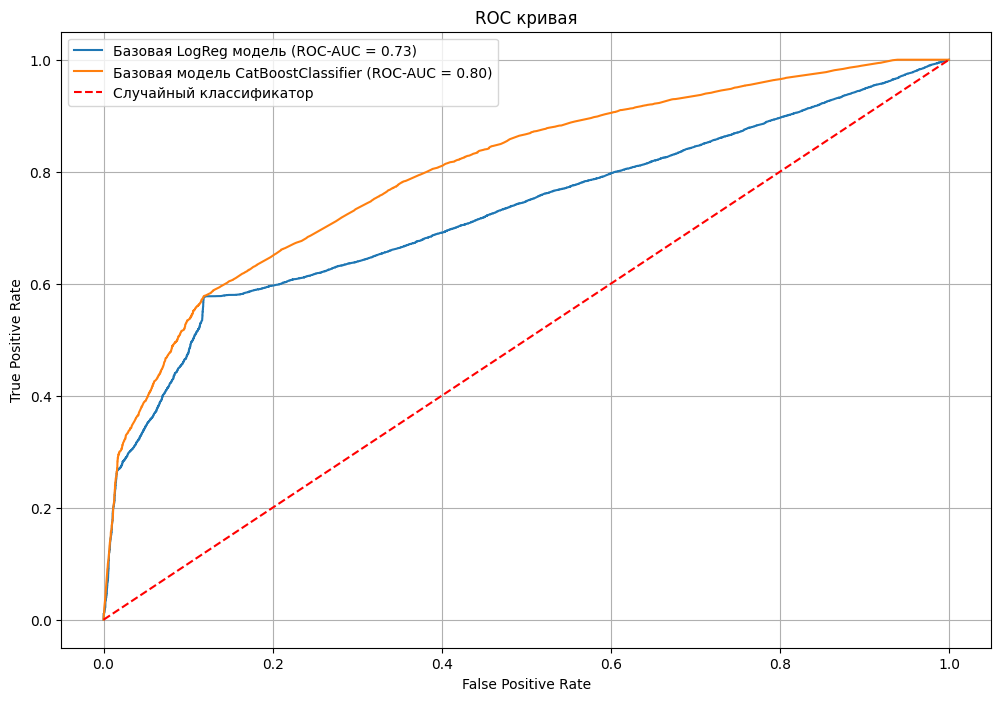

In [52]:
plot_auc_roc_curve(
    y_val, 
    [y_proba_logreg_val_pred, y_proba_val_cbr_model_base], 
    labels=['Базовая LogReg модель', 'Базовая модель CatBoostClassifier']
)

Анализ:
- baseline Logreg и CatBoost показывает хорошее качество предсказаний на валидационной выборке: 
    - CatBoost: ROC-AUC ~= 0.8
    - Logreg: ROC-AUC ~= 0.73

Вывод:
- построены качественные baseline модели, предсказания которых существенно лучше случайного классификатора
- качество предсказаний CatBoost выше


##  Кластеризация по признакам, связанным с местоположением



In [53]:
# маски для разбиения на train/validate/test
train_mask = df_customers_filtered['customer_id'].isin(df_train['customer_id'])
validate_mask = df_customers_filtered['customer_id'].isin(df_val['customer_id'])
test_mask = df_customers_filtered['customer_id'].isin(df_test['customer_id'])

df_customers_train = df_customers_filtered[train_mask]
df_customers_val = df_customers_filtered[validate_mask]
df_customers_test = df_customers_filtered[test_mask]

### Формирование гео-кластеров

In [54]:
# Преобразование для KMeans
lat_lon_feat = ['customer_lat',	'customer_lon']
k_means_geo_preproc = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), lat_lon_feat),
    ]
)

In [55]:
def plot_elbow_k_means(k_means_preproc, df, ks: list = list(range(2, 12))):
	wcss = []

	for k in ks:
		pipe = Pipeline(
			steps=[
				("prep", k_means_preproc),
				('model', KMeans(n_clusters=k, init="k-means++", random_state=RANDOM_SEED)),
			]
		)
		pipe.fit(df)
		inertia = pipe['model'].inertia_  # извлеките значение WCSS из модели в пайплайне
		wcss.append(inertia)      # добавьте полученное значение к списку wcss

	plt.plot(list(ks), wcss)    # постройте график WCSS
	plt.title('Зависимость метрки качества разбиения от кол-ва кластеров KMeans')
	plt.xticks(list(ks))  # добавьте количество кластеров по оси X
	plt.xlabel('кол-во кластеров')
	plt.ylabel('Инерция')
	plt.grid()
	plt.show()

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-pac

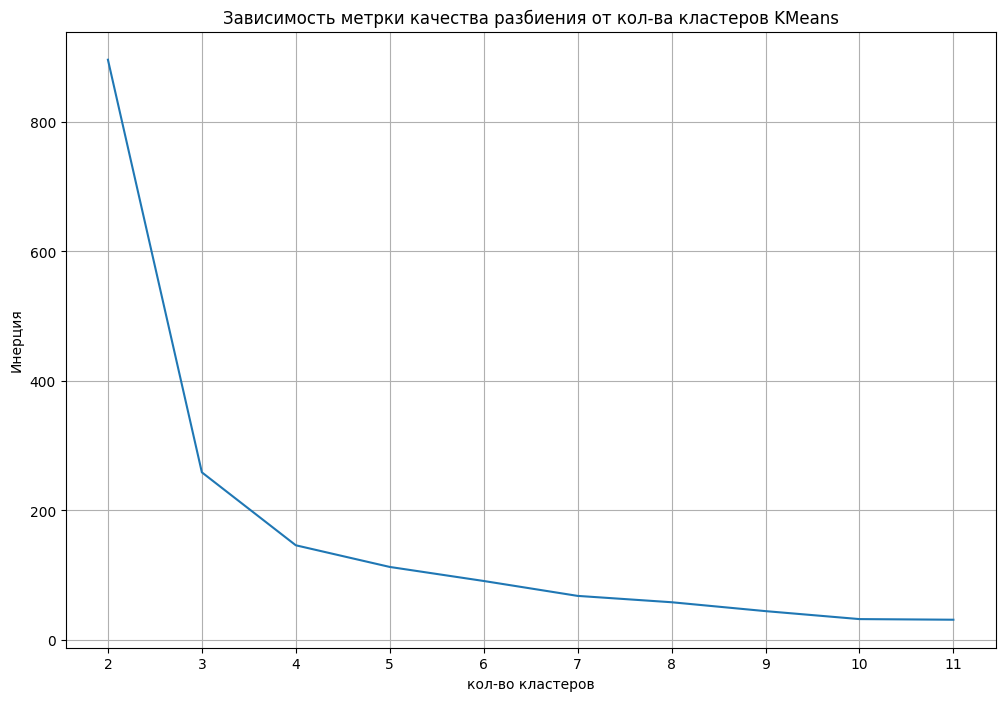

In [56]:
plot_elbow_k_means(k_means_preproc=k_means_geo_preproc, df=df_customers_train)

Анализ:
- по графику можно сделать вывод, что разбиение более, чем на 4 кластеров не дает существенного снижения метрики качества разбиения.

Вывод:
- для кластеризации следует использовать 4 кластеров

In [57]:
kmeans_geo_pipe = Pipeline(
    steps=[
        ('prep', k_means_geo_preproc),
        ('kmeans', KMeans(n_clusters=4, init="k-means++", random_state=RANDOM_SEED)),
    ]
)
kmeans_geo_pipe.fit(df_customers_train)
kmeans = kmeans_geo_pipe.named_steps["kmeans"]

kmeans

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-pac

KMeans(n_clusters=4, random_state=42)

In [68]:
def plot_clusters(labels, points):
    # Создаем график
    fig, ax = plt.subplots()
    plt.axis('equal') 

    # Получаем уникальные кластеры
    unique_clusters = np.unique(labels)
    n_clusters = len(unique_clusters)

    # Палитра цветов
    colors = plt.cm.Set3(np.linspace(0, 1, n_clusters))

    # Центроиды кластеров
    centroids = []

    # Рисуем точки
    for i, cluster_id in enumerate(unique_clusters):
        mask = labels == cluster_id
        cluster_points = points[mask]
        
        # Вычисляем центроид
        centroid = np.mean(cluster_points, axis=0)
        centroids.append(centroid)
        
        # Рисуем точки кластера
        ax.scatter(cluster_points[:, 1], cluster_points[:, 0], 
                            c=[colors[i]], label=f'Кластер {cluster_id}', 
                    )
        
        # Рисуем центроид
        ax.scatter(centroid[1], centroid[0], 
                c=[colors[i]], s=20, marker='X', 
                edgecolors='black')

    # Добавляем аннотации центроидов
    for i, (centroid, cluster_id) in enumerate(zip(centroids, unique_clusters)):
        ax.annotate(f'C{cluster_id}', 
                    (centroid[1], centroid[0]),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=10, fontweight='bold')

    # Настраиваем график
    ax.set_title('Визуализация кластеров с центроидами')
    ax.set_xlabel('lat scaled')
    ax.set_ylabel('lon scaled')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3, linestyle='--')
    


    # Статистика
    stats_text = f'Всего точек: {len(points)}\nКластеров: {n_clusters}'
    for i, cluster_id in enumerate(unique_clusters):
        count = np.sum(labels == cluster_id)
        stats_text += f'\nКластер {cluster_id}: {count} точек'

    ax.text(0.7, 0.98, stats_text, 
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7),
            fontsize=10)

    plt.tight_layout()
    plt.show()

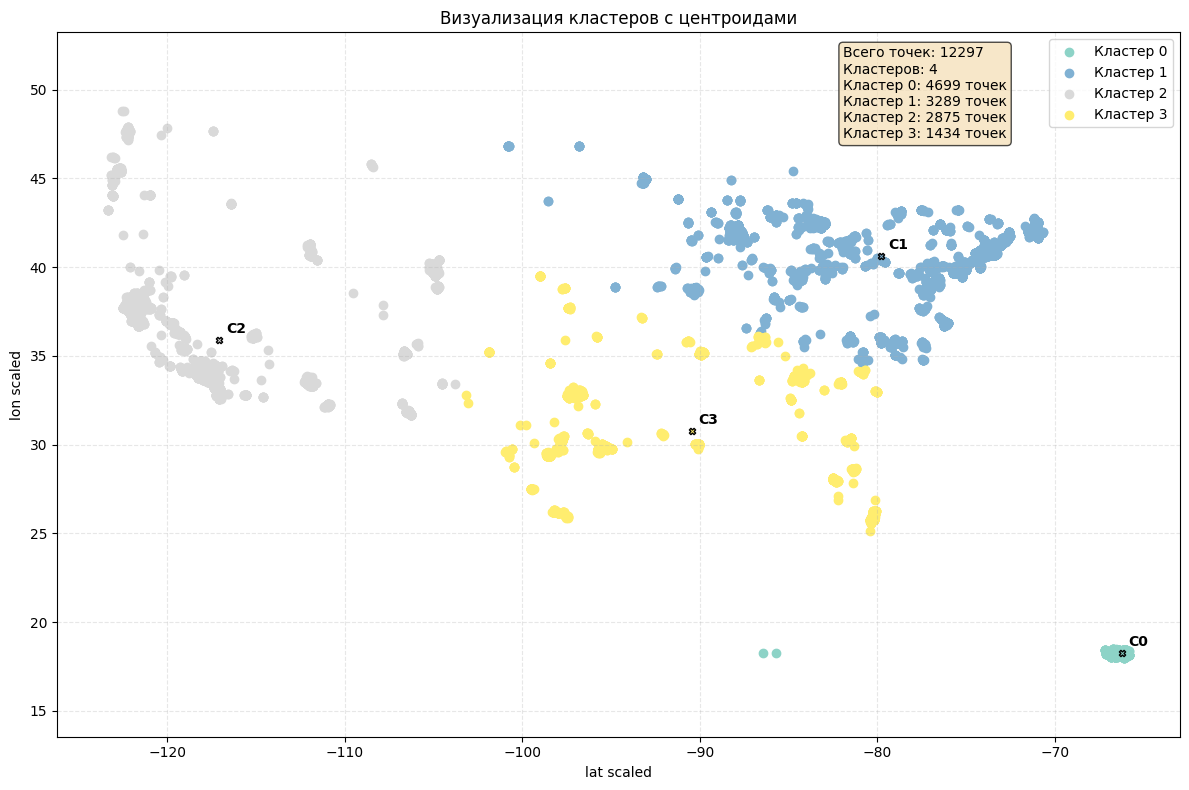

In [69]:
# Перевод представления признаков X обучающей выборки в пространство KMeans 
X_train_emb = kmeans_geo_pipe.named_steps["prep"].transform(df_customers_train)

# Получаем метки кластеров
train_cluster = kmeans.predict(X_train_emb)

# Центры кластеров
points_coords = df_customers_train[lat_lon_feat].values

plot_clusters(labels=train_cluster, points=points_coords)

Анализ:
- кластеры четко отделены друг от друга
- точки локализованы сблизи центров своих кластеров

Вывод:
- можно ввести географический признак для клиентов, отражающий их принадлежность к одному из 4 кластеров

In [70]:
def add_geo_features(kmeans_pipe_fitted, X_lat_lon):
    """
    Преобразование географических признаков:
        - 'customer_lat', 'customer_lon' переходят в признак географического кластера
    """

    # Перевод представления признаков X_lat_lon в пространство KMeans 
    X_emb = kmeans_pipe_fitted.named_steps["prep"].transform(X_lat_lon)

    # Расстояния от объекта до центра каждого кластера
    kmeans = kmeans_pipe_fitted.named_steps["kmeans"]
    # Получаем метки кластеров
    X_cluster = kmeans.predict(X_emb)

    # Центры кластеров
    X_centers = kmeans.cluster_centers_[X_cluster]
    X_dist_to_own = np.sqrt(((X_emb - X_centers) ** 2).sum(axis=1))


    # DataFrame с кластерной меткой и расстоянием до своего центра
    X_meta_df = pd.DataFrame(
        {
            "geo_cluster_id": X_cluster,
            "dist_to_own_geo_center": X_dist_to_own
        },
        index=X_lat_lon.index
    )

    # Создание расширенного датасета с дополнительными фичами от кластеризации
    X_w_cluster = pd.merge(X_lat_lon, X_meta_df, left_index=True, right_index=True)

    return X_w_cluster


In [71]:
add_geo_features(kmeans_pipe_fitted=kmeans_geo_pipe, X_lat_lon=df_customers_train)

,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency,geo_cluster_id,dist_to_own_geo_center
2,3,18.025375,-66.615082,3189.200037,5,0.105000,0.0,230,0,0.009856
4,5,18.359104,-66.077911,1101.919998,3,0.140000,0.0,458,0,0.004456
7,8,34.028275,-118.239136,3411.270008,8,0.092632,0.0,127,2,0.063484
8,9,18.025280,-66.613068,2947.460070,5,0.097143,0.0,141,0,0.009835
9,10,38.471359,-77.414200,1130.050007,2,0.085000,0.0,308,1,0.081342
...,...,...,...,...,...,...,...,...,...,...
20643,20749,29.891226,-95.294243,209.350006,1,0.030000,0.0,1,3,0.088731
20644,20750,18.291523,-66.037064,211.500000,1,0.020000,0.0,1,0,0.003696
20646,20752,40.677719,-73.963120,215.820007,1,0.000000,0.0,1,1,0.101075
20647,20753,18.273024,-66.037056,161.869995,1,0.250000,0.0,1,0,0.003527


##  Кластеризация по признакам профилей клиентов



In [72]:
customers_key_features = [
    'recency', 'total_orders', 
    'total_sales', 'return_rate', 
    'avg_discount',
]

# исследование методом локтя
# Преобразование для KMeans
k_means_cust_preproc = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), customers_key_features),
    ]
)


/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-pac

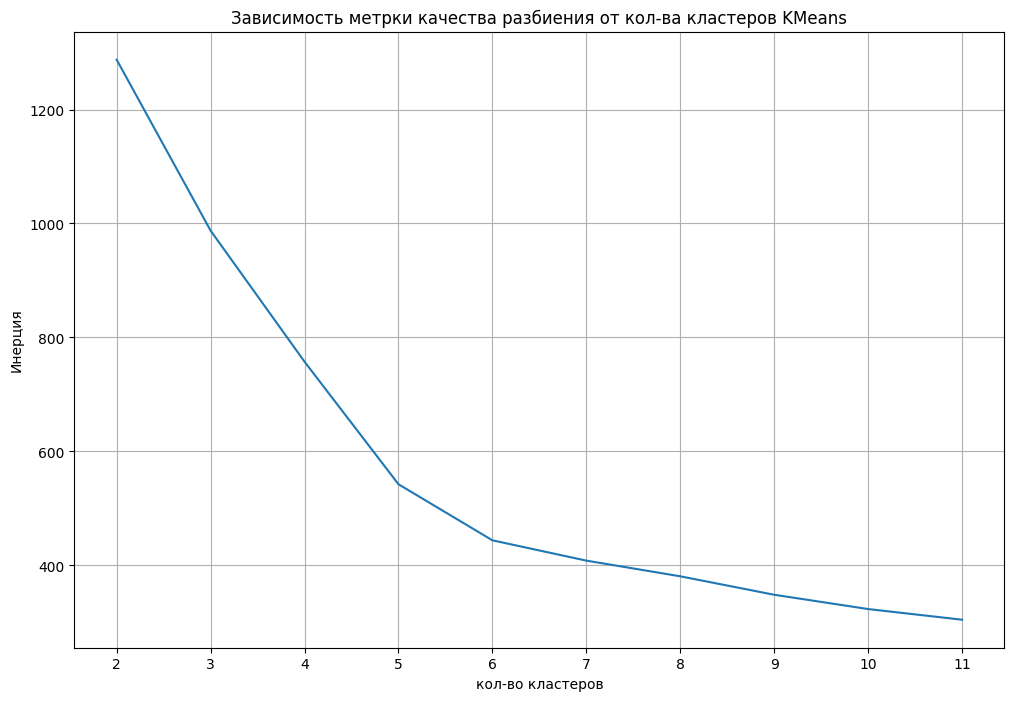

In [73]:
plot_elbow_k_means(k_means_preproc=k_means_cust_preproc, df=df_customers_train)

Анализ:
- разбиение более чем на 7 кластеров не дает существенного снижения метрики разбиения

Итог:
- целесообразно выделить 7 кластеров в данных по поведению клиентов

In [74]:
def add_customers_behaviuor_features(kmeans_pipe_fitted, X_customers: pd.DataFrame):
    """
    Добавление к датасету поведенческих признаков
    """

    # Перевод представления признаков X_customers в пространство KMeans 
    X_emb = kmeans_pipe_fitted.named_steps["prep"].transform(X_customers)

    # Расстояния от объекта до центра каждого кластера
    kmeans = kmeans_pipe_fitted.named_steps["kmeans"]
    # Получаем метки кластеров
    X_cluster = kmeans.predict(X_emb)

    # Центры кластеров
    X_centers = kmeans.cluster_centers_[X_cluster]
    X_dist_to_own = np.sqrt(((X_emb - X_centers) ** 2).sum(axis=1))


    # DataFrame с кластерной меткой и расстоянием до своего центра
    X_meta_df = pd.DataFrame(
        {
            "cust_cluster_id": X_cluster,
            "dist_to_own_cust_center": X_dist_to_own
        },
        index=X_customers.index
    )

    # Создание расширенного датасета с дополнительными фичами от кластеризации
    X_w_cluster = pd.merge(X_customers, X_meta_df, left_index=True, right_index=True)

    return X_w_cluster

In [75]:
kmeans_cust_pipe = Pipeline(
    steps=[
        ('prep', k_means_cust_preproc),
        ('kmeans', KMeans(n_clusters=7, init="k-means++", random_state=RANDOM_SEED)),
    ]
)

In [76]:
kmeans_cust_pipe.fit(X=df_customers_train[customers_key_features])

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-pac

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', MinMaxScaler(),
                                                  ['recency', 'total_orders',
                                                   'total_sales', 'return_rate',
                                                   'avg_discount'])])),
                ('kmeans', KMeans(n_clusters=7, random_state=42))])

In [77]:
df_customers_train_tsne = add_customers_behaviuor_features(
    kmeans_pipe_fitted=kmeans_cust_pipe, X_customers=df_customers_train
)
df_customers_train_tsne = add_geo_features(kmeans_pipe_fitted=kmeans_geo_pipe, X_lat_lon=df_customers_train_tsne)
df_customers_train_tsne

,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency,cust_cluster_id,dist_to_own_cust_center,geo_cluster_id,dist_to_own_geo_center
2,3,18.025375,-66.615082,3189.200037,5,0.105000,0.0,230,2,0.068280,0,0.009856
4,5,18.359104,-66.077911,1101.919998,3,0.140000,0.0,458,4,0.230319,0,0.004456
7,8,34.028275,-118.239136,3411.270008,8,0.092632,0.0,127,6,0.172660,2,0.063484
8,9,18.025280,-66.613068,2947.460070,5,0.097143,0.0,141,2,0.120200,0,0.009835
9,10,38.471359,-77.414200,1130.050007,2,0.085000,0.0,308,4,0.129894,1,0.081342
...,...,...,...,...,...,...,...,...,...,...,...,...
20643,20749,29.891226,-95.294243,209.350006,1,0.030000,0.0,1,0,0.090088,3,0.088731
20644,20750,18.291523,-66.037064,211.500000,1,0.020000,0.0,1,0,0.123314,0,0.003696
20646,20752,40.677719,-73.963120,215.820007,1,0.000000,0.0,1,0,0.197453,1,0.101075
20647,20753,18.273024,-66.037056,161.869995,1,0.250000,0.0,1,1,0.324649,0,0.003527


### Бизнес интерпретация кластеров клиентов


#### расчет RFM-метрик для интерпретации кластеров

In [78]:
# Исходные средние по кластерам
cluster_rfm = df_customers_train_tsne.groupby('cust_cluster_id')[['total_sales', 'total_orders', 'recency']].mean()

rfm_rank = cluster_rfm.copy()

# Ранжирование по каждой метрике
rfm_rank['rank_sales']   = rfm_rank['total_sales'].rank(ascending=False, method='dense')   # чем больше, тем лучше
rfm_rank['rank_orders']  = rfm_rank['total_orders'].rank(ascending=False, method='dense')  # чем больше, тем лучше
rfm_rank['rank_recency'] = rfm_rank['recency'].rank(ascending=True, method='dense')        # чем меньше, тем лучше

# Сумма рангов (общий скоринг)
rfm_rank['rank_sum'] = rfm_rank[['rank_sales', 'rank_orders', 'rank_recency']].sum(axis=1)

# Сортировка по сумме рангов (лучшие – с наименьшей суммой)
rfm_rank_sorted = rfm_rank.sort_values('rank_sum')

rfm_rank_sorted[['total_sales', 'total_orders', 'recency', 
                       'rank_sales', 'rank_orders', 'rank_recency', 'rank_sum']]


,total_sales,total_orders,recency,rank_sales,rank_orders,rank_recency,rank_sum
cust_cluster_id,,,,,,,
6,4686.295457,8.148804,231.747564,1.0,1.0,4.0,6.0
2,2969.198784,5.492590,257.653666,2.0,2.0,5.0,9.0
4,1642.478112,3.283408,280.535426,3.0,3.0,6.0,12.0
3,469.669156,1.298305,151.111864,5.0,5.0,3.0,13.0
0,290.683597,1.020741,65.803704,6.0,7.0,1.0,14.0
1,262.909147,1.027841,68.204473,7.0,6.0,2.0,15.0
5,1376.971691,2.664983,676.345118,4.0,4.0,7.0,15.0


Анализ:
- 2 и 6 - наиболее лояльные клиенты. Имеют больше всего покупок и принесли компании наибольшую прибыль
- 0 и 1 - новички. Только недавно начали сотрудничать и сделали мало заказов

Вывод:
- кластеризация позволила разделить новичков с малым количесвтом заказов и давних прибыльных клиентов

#### Оценка по добропорядочности (Return Rate)

In [79]:
df_customers_train_tsne.groupby('cust_cluster_id')['return_rate'].mean().sort_values()

cust_cluster_id
0    0.000000
1    0.000183
5    0.022803
4    0.027967
6    0.043193
2    0.046404
3    0.936177
Name: return_rate, dtype: float64

Анализ:
- 0 и 1 - наиболее добропорядочные. Они недавно начали заказывать и пока у них малая доля проблемных заказов
- 2,4,5,6 - средняя группа по добропорядочности. Средняя доля проблемных заказов 2-5%
- 3 - самые недобропорядочные. Средняя доля проблемных заказов зашкаливает: 93%

Вывод:
- кластеризация позволила отделить группу проблемных клиентов

#### Средняя скидка (avg_discount)

In [80]:
df_customers_train_tsne.groupby('cust_cluster_id')['avg_discount'].mean().sort_values()

cust_cluster_id
0    0.047171
6    0.100437
5    0.100777
4    0.101341
2    0.102029
3    0.106225
1    0.170270
Name: avg_discount, dtype: float64

Анализ:
- 0 - наименьшая средняя скидка: ~=5%
- 2-6 - средняя скидка около 10%
- 1 - самый высокий показатель 17%

вывод:
- по средней скидке кластеризация впозволила выделить 3 основных группы клиентов: высокая-средняя-низкая средняя скидка

#### t-SNE визуализация

In [81]:
# Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_customers_train_tsne)

# 1. Создаём модель t-SNE и фиксируем ключевые параметры проекции
tsne = TSNE(
    n_components=2, # выбираем 2D-координаты
    perplexity=50, # масштаб локального окружения
    init="pca", # стартовая инициализация через PCA
    random_state=RANDOM_SEED, # фиксируем случайность для воспроизводимости
    learning_rate="auto"
)
# 2. Запускаем оптимизацию и получаем матрицу координат (n_samples, 2)
X_tsne = tsne.fit_transform(X_scaled)

# 3. Упаковываем координаты в таблицу для дальнейшей визуализации
tsne_df = pd.DataFrame(X_tsne, columns=["tsne_1", "tsne_2"])
tsne_df.head() # координаты объектов на плоскости

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packag

,tsne_1,tsne_2
0,3.218447,-67.131302
1,33.934238,-39.931900
2,67.330650,30.006706
3,-0.277090,-66.311142
4,-2.110627,1.937108


In [82]:
def plot_tsne_diagram(df: pd.DataFrame, df_tsne: pd.DataFrame, color_feature: str):
    
    # сохраняем признак для раскраски и добавляем в таблицу
    color_values = df[color_feature].values
    df_tsne[color_feature] = color_values

    # Строим диаграмму рассеяния
    scatter = plt.scatter(
        df_tsne["tsne_1"],
        df_tsne["tsne_2"],
        c=df_tsne[color_feature],
        s=12,
        alpha=0.7,
    )

    plt.title(f"t-SNE: визуализация объектов по признакам {color_feature}")
    plt.xlabel("tsne_1")
    plt.ylabel("tsne_2")
    plt.colorbar(scatter, label=color_feature)

    plt.tight_layout()
    plt.show()

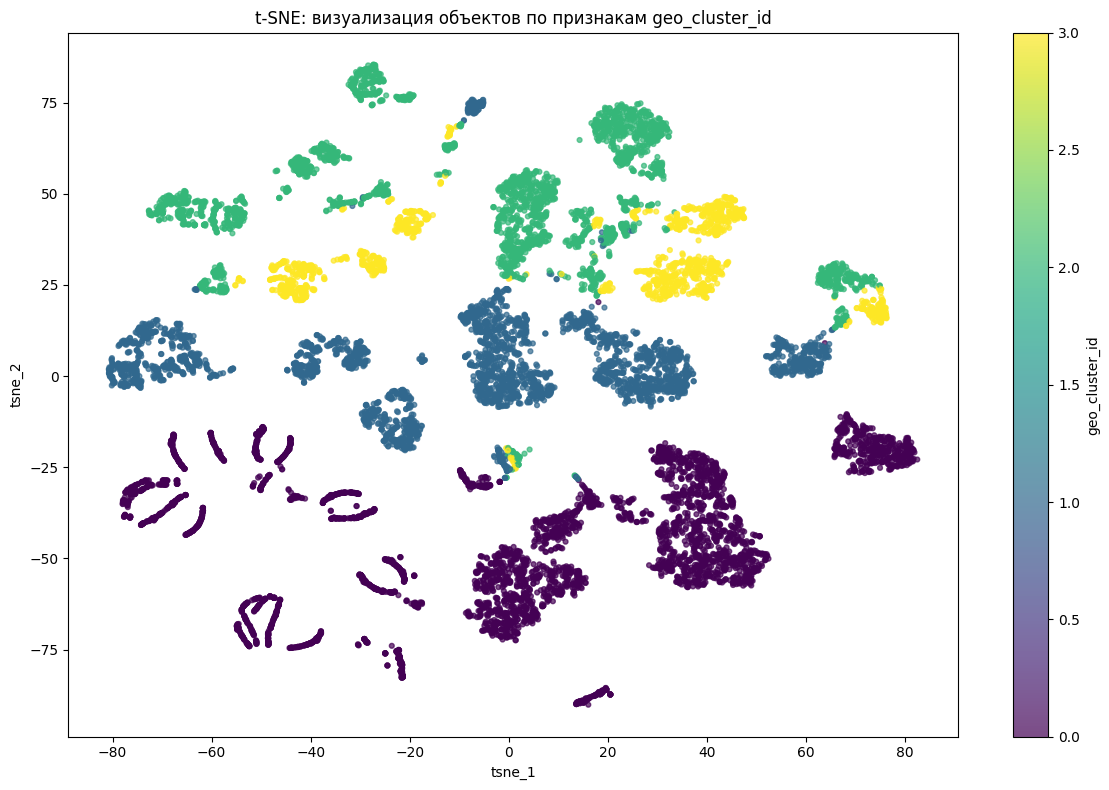

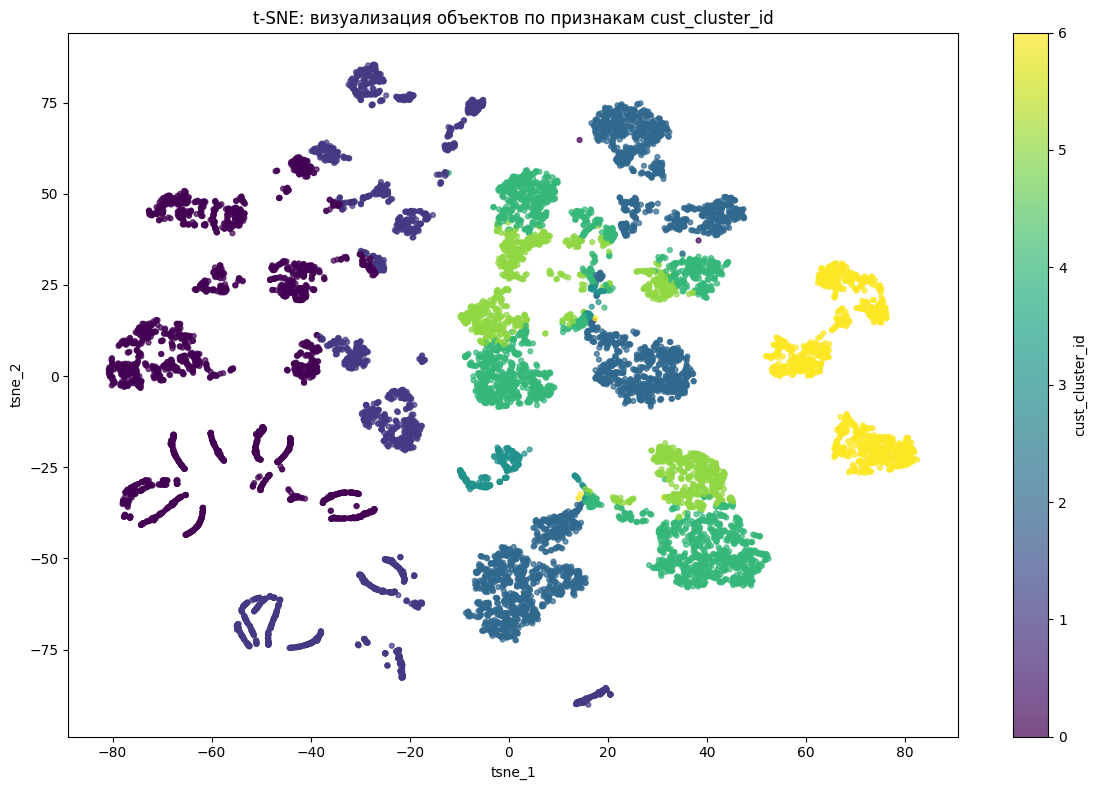

In [83]:
customers_key_features = [
    'geo_cluster_id',
    'cust_cluster_id',
]
for feature in customers_key_features:
    plot_tsne_diagram(
        df=df_customers_train_tsne, 
        df_tsne=tsne_df, 
        color_feature=feature
    )

Анализ:
- на графиках четко просматриваются кластеры по сформированным признакам geo_cluster_id и cust_cluster_id. Это cвидетельствует об инормативности разбиения 

Вывод:
- сформированные по географии и поведению клиентов кластеры рекомендуется использовать в качестве новых признаков. (geo_cluster_id и cust_cluster_id)

##  Обучение модели на новых признаках

#### Подготовка данных

In [84]:
def get_kmeans_geo_pipe():
    lat_lon_feat = ['customer_lat',	'customer_lon']
    k_means_geo_preproc = ColumnTransformer(
        transformers=[
            ("num", MinMaxScaler(), lat_lon_feat),
        ]
    )
    kmeans_geo_pipe = Pipeline(
        steps=[
            ('prep', k_means_geo_preproc),
            ('kmeans', KMeans(n_clusters=5, init="k-means++", random_state=RANDOM_SEED)),
        ]
    )
    return kmeans_geo_pipe

def get_kmeans_cust_pipe():
    customers_key_features = [
        'recency', 'total_orders', 
        'total_sales', 'return_rate', 
        'avg_discount',
    ]

    k_means_cust_preproc = ColumnTransformer(
        transformers=[
            ("num", MinMaxScaler(), customers_key_features),
        ]
    )
    kmeans_cust_pipe = Pipeline(
        steps=[
            ('prep', k_means_cust_preproc),
            ('kmeans', KMeans(n_clusters=7, init="k-means++", random_state=RANDOM_SEED)),
        ]
    )
    return kmeans_cust_pipe


In [85]:

kmeans_geo_pipe = get_kmeans_geo_pipe()
kmeans_cust_pipe = get_kmeans_cust_pipe()

df_customers_train_filtered = filter_geo_data(df=df_customers_train)

kmeans_geo_cluster = kmeans_geo_pipe.fit_predict(X=df_customers_train_filtered)
kmeans_cust_cluster = kmeans_cust_pipe.fit_predict(X=df_customers_train_filtered)

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-pac

In [86]:
def to_categorical(df: pd.DataFrame, feat_names):
    """приведение к pd.categorical"""
    df_upd = df.copy()
    df_upd[feat_names] = df[feat_names].astype('category')

    return df_upd


def feature_engineering(
    X_orders: pd.DataFrame, 
    X_customers: pd.DataFrame, 
    kmeans_b_pipe_fitted: Pipeline, 
    kmeans_g_pipe_fitted: Pipeline,
):
    """Формирование итогового признакового пространства"""

    # фильтрация по географии и добавление признаков кластеров
    X_customers_filtered = filter_geo_data(df=X_customers)
    X_customers_with_b_clusters = add_customers_behaviuor_features(kmeans_b_pipe_fitted, X_customers_filtered)
    df_customers_with_b_g_clusters = add_geo_features(kmeans_g_pipe_fitted, X_customers_with_b_clusters)

    # перевод кластеров в категориальные признаки
    feat_to_cat = ['cust_cluster_id', 'geo_cluster_id']
    df_customers_with_b_g_clusters = to_categorical(df_customers_with_b_g_clusters, feat_to_cat)

    # устранение избыточности
    redundant_feats = ['customer_lat',	'customer_lon', 'order_id',	'customer_id']
    return pd.merge(
        left=X_orders,
        right=df_customers_with_b_g_clusters,
        how='inner',
        on='customer_id'
    ).drop(columns=redundant_feats)


In [87]:
df_train_mod = feature_engineering(
    X_orders=df_train, 
    X_customers=df_customers_train, 
    kmeans_b_pipe_fitted=kmeans_cust_pipe,
    kmeans_g_pipe_fitted=kmeans_geo_pipe
)

df_val_mod = feature_engineering(
    X_orders=df_val, 
    X_customers=df_customers_val, 
    kmeans_b_pipe_fitted=kmeans_cust_pipe,
    kmeans_g_pipe_fitted=kmeans_geo_pipe
)

df_test_mod = feature_engineering(
    X_orders=df_test, 
    X_customers=df_customers_test, 
    kmeans_b_pipe_fitted=kmeans_cust_pipe,
    kmeans_g_pipe_fitted=kmeans_geo_pipe
)

df_train_mod.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107661 entries, 0 to 107660
Data columns (total 16 columns):
 #   Column                   Non-Null Count   Dtype   
---  ------                   --------------   -----   
 0   late_delivery_risk       107661 non-null  int64   
 1   shipping_mode            107661 non-null  category
 2   category_name            107661 non-null  category
 3   item_price               107661 non-null  float64 
 4   order_month              107661 non-null  category
 5   order_weekday            107661 non-null  category
 6   order_hour               107661 non-null  category
 7   total_sales              107661 non-null  float64 
 8   total_orders             107661 non-null  int64   
 9   avg_discount             107661 non-null  float64 
 10  return_rate              107661 non-null  float64 
 11  recency                  107661 non-null  int64   
 12  cust_cluster_id          107661 non-null  category
 13  dist_to_own_cust_center  107661 non-null  fl

In [88]:
X_train_mod = df_train_mod.drop(columns=target_name)
y_train_mod = pd.Series(data=df_train_mod[target_name], name='target')

X_val_mod = df_val_mod.drop(columns=target_name)
y_val_mod = pd.Series(data=df_val_mod[target_name], name='target')

X_test_mod = df_test_mod.drop(columns=target_name)
y_test_mod = pd.Series(data=df_test_mod[target_name], name='target')


#### Обучение LogReg

In [89]:
baseline_logreg_model = LogisticRegression(
    random_state=RANDOM_SEED, class_weight="balanced",
    max_iter=1000, penalty='elasticnet', solver='saga', l1_ratio=0.5
)

baseline_logreg_pipeline = Pipeline(
    steps=[
        ('preproc', create_preprocessor()),
        ('model', baseline_logreg_model)
    ]
)

baseline_logreg_pipeline.fit(X_train_mod, y_train_mod)

# проверка на валидационной выборке
y_logreg_val_pred_mod = baseline_logreg_pipeline.predict(X_val_mod)
y_proba_logreg_val_pred_mod = baseline_logreg_pipeline.predict_proba(X_val_mod)[:, 1]

/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/a.plahotniuc/Workspace/practicum_ds/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encoun

#### Обучение CatBoostClassifier

In [90]:
cat_cols, _ = get_cat_num_cols(df=X_train_mod)
cat_cols

['shipping_mode',
 'category_name',
 'order_month',
 'order_weekday',
 'order_hour',
 'cust_cluster_id',
 'geo_cluster_id']

In [91]:
cbc_model_mod_feat = CatBoostClassifier(
    random_state=RANDOM_SEED,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=50,
    use_best_model=True,
    verbose=False,
    n_estimators=1500,
    cat_features=cat_cols
)

In [92]:
cbc_model_mod_feat.fit(
    X=X_train_mod, 
    y=y_train_mod,
    eval_set=(X_val_mod, y_val_mod),
    verbose=False,
    use_best_model=True
)
# предсказания на validate
y_proba_val_cbr_model_mod = cbc_model_mod_feat.predict_proba(X_val_mod)[:, 1]
y_pred_val_cbr_model_mod = cbc_model_mod_feat.predict(X_val_mod)

####  Оценка качества моделей

In [93]:
total_result_df = pd.concat([
    result_df,
    evaluate_model(y_true_binary=y_val_mod, y_pred_probas=y_proba_logreg_val_pred_mod, name='logreg_mod_feat'),
    evaluate_model(y_true_binary=y_val_mod, y_pred_probas=y_proba_val_cbr_model_mod, name='cbc_mod_feat'),
]).sort_values(by='roc_auc_score', ascending=False)
total_result_df

,name,roc_auc_score
0,cbc_mod_feat,0.803654
0,catboost_base,0.801536
0,logreg_mod_feat,0.745248
0,baseline_logreg,0.726176


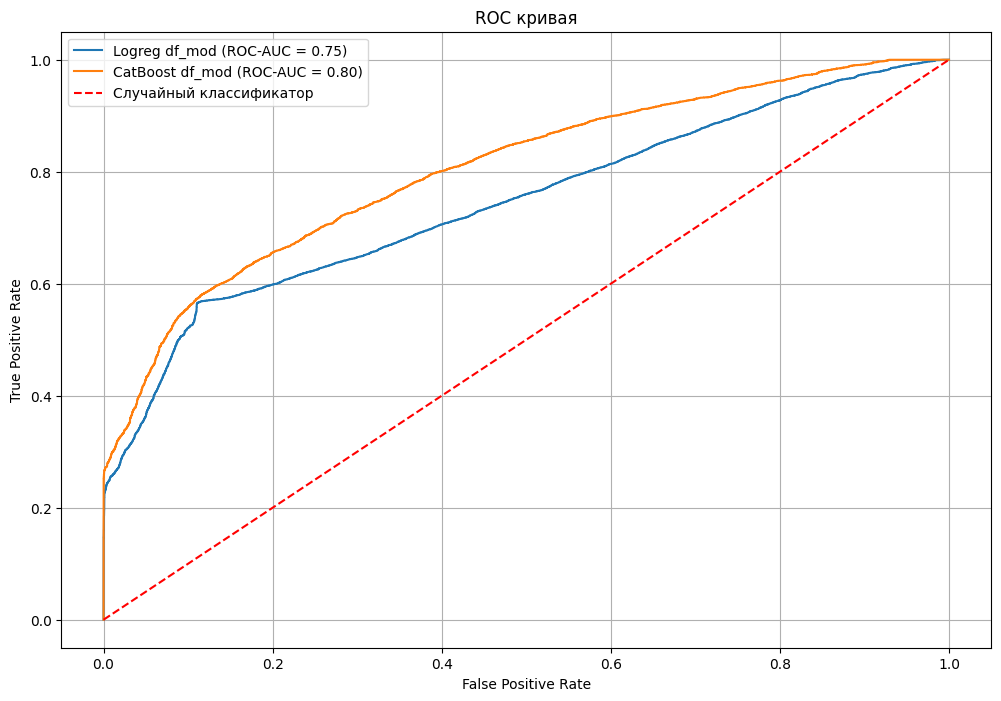

In [94]:
plot_auc_roc_curve(
    y_val_mod, 
    [y_proba_logreg_val_pred_mod, y_proba_val_cbr_model_mod],
    labels=['Logreg df_mod', 'CatBoost df_mod']
)

Анализ:
- обучение на датасете с новыми признаками позволило несущественно улучшить качество предсказания моделей
- модели CatBoost, обученная на новых признаках, показала наилучший результат по ключевой метрики ROC-AUC = 0.803

Итог:
- определена лучшая модель: CatBoost, обученная на новых признаках

## Тестирование лучшей модели

#### Оценка на test

In [95]:
y_proba_test_cbr_model_mod = cbc_model_mod_feat.predict_proba(X_test_mod)[:, 1]
y_test_cbr_model_mod = cbc_model_mod_feat.predict(X_test_mod)

In [96]:
evaluate_model(y_true_binary=y_test_mod, y_pred_probas=y_proba_test_cbr_model_mod, name='cbc_mod_test')

,name,roc_auc_score
0,cbc_mod_test,0.801615


Анализ:
- лучшая модель показывает высокое качество на test, ключевая метрика ROC-AUC = 0.8 > 0.75 

Итог:
- модель удовлетворяет требованиям заказчика и рекомендована к внедерению

#### Матрица ошибок

In [97]:
def plot_confusion_matrices(y_true_test, y_pred_test, class_names=['ОК - 0', 'Задержка доставки - 1']):

    cm_test = confusion_matrix(y_true_test, y_pred_test)
    disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=class_names)
    disp_test.plot(cmap='Blues', values_format='d')
    plt.title('Матрица ошибок. Тестовые данные')

    plt.tight_layout()
    plt.show()

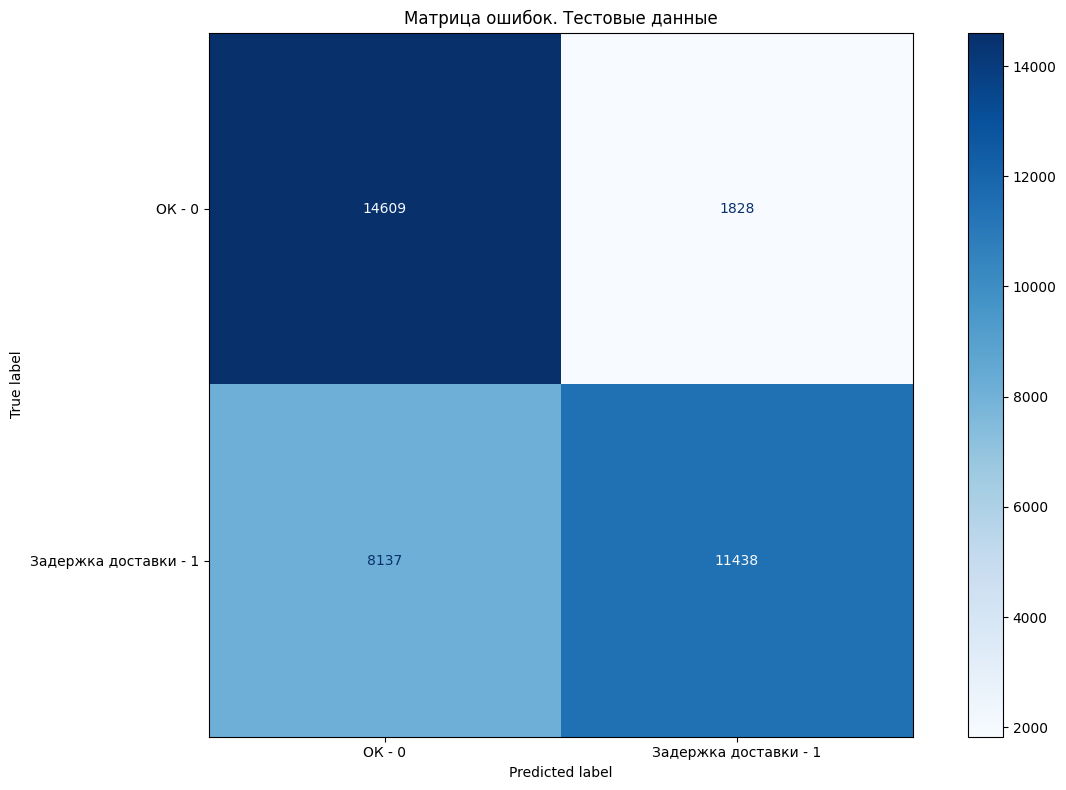

In [98]:
plot_confusion_matrices(y_true_test=y_test_mod, y_pred_test=y_test_cbr_model_mod)

Анализ:
- матрица ошибок имеет преимущественно диагональный вид: модель чаще предсказывает корректный класс
- модель часто ошибается, предсказывая отсутствие задержки, в то время как она действительно случается 

Итог:
- несмотря на выполнение требований по ключевой метрике, модель достаточно часто не предсказывает задержку, в то время как она случается. Модель может быть улучшена за счет калибровки и подбора оптимального порога 

#### Анализ важности признаков

In [99]:
def show_shap_analysis(model, name, X_data):
    
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_data)

    fig, axes = plt.subplots(2, 1)

    plt.sca(axes[0])
    shap.summary_plot(shap_values, X_data, plot_type="dot", show=False)
    axes[0].set_title(
        f"Распределение влияния признаков для {name}", fontsize=14, pad=15
    )

    plt.sca(axes[1])
    shap.summary_plot(shap_values, X_data, plot_type="bar", show=False)
    axes[1].set_title(
        f"Глобальная важность (средний |SHAP|) для {name}",
        fontsize=14,
        pad=15,
    )

    plt.tight_layout()
    plt.show()


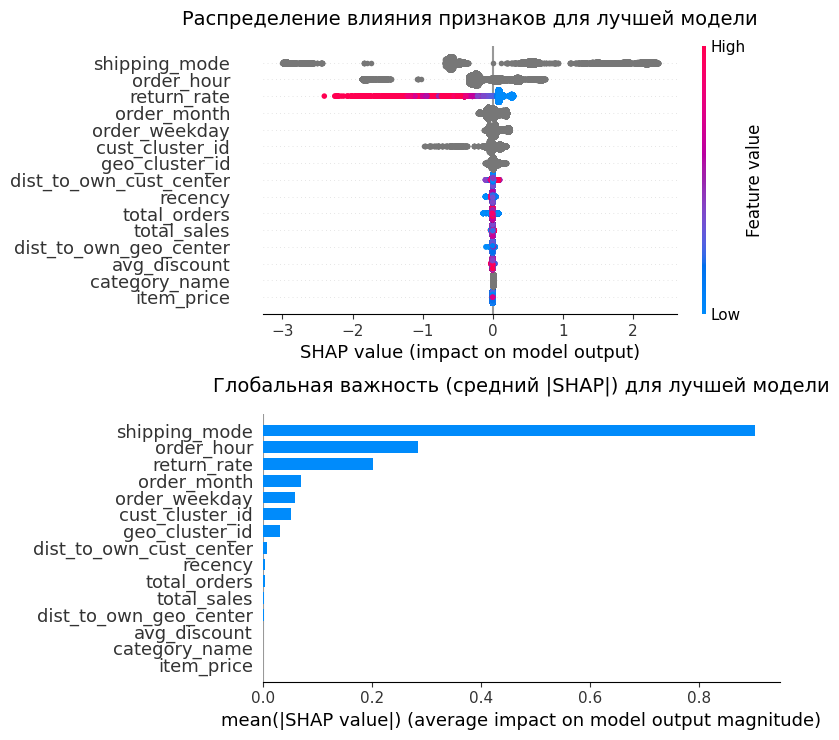

In [100]:
show_shap_analysis(cbc_model_mod_feat, 'лучшей модели', X_test_mod)

Анализ:
- наиболее важными признаками являются: 
    - shipping_mode - вид доставки самый важный признак
    - return_rate - чем ниже показатель доли проблемных заказов, тем ниже вероятность задержки 
    - order_hour, order_weekday, order_month - времо совершения покупки сильно влияет на вероятность задержки 
    - сформированные признаки кластеров существенно менее важные для модели (базовые признаки остались более информативными). Однако кластерные признаки входят в топ-7 по значимости (из 15 признаков)

##  Выводы и рекомендации

**Результаты моделирования.** 

В ходе исследования удалось сформировать качественную baseline модель и улучшить ее показатели за счет введения новых признаков, основанных на применении кластеризации.
Базовая модель на валидации: ROC-AUC = 0.801, С новыми признаками ROC-AUC =  0.803
Итоговое значение ROC-AUC на тестовой выборке: 0.801. 
Разработанная модель удовлетворяет требованиям по ключевой метрике и рекомендована к внедерению.

**Эффективность сегментации.** 

Кластеризация по географическим признакам и профилю клиента не дала ощутимого прироста по качеству итоговой модели (+0.2%). Анализ важности признаков показал, что признаки вида доставки, доля проблемных заказов и время заказа существенно более важные признаки, нежели новые кластерные. Таким образом, гипотеза о влиянии кластерных признаков на риск задержки не подтвердилась.
Среди кластерных признаков наиболее информативный для модели является поведенческий признак.

**Технический инсайт.** 

Проводились эксперименты с разным количеством кластеров. Выбрано оптимальное кол-во кластеров по методу локтя:
- географические кластеры: 4 кластера 
- поведенческие кластеры: 7 кластеров 
Большее кол-во кластеров модет вредить качеству прогноза, поскольку будет подстраиваться под несущественный шум в данных, а не выявлять общую закономерность 

**Бизнес-рекомендации.** 

Компания CargaPronto может использовать разработанную модель для предсказания задержек в поставках следующим образом:
- при получении высокой вероятности задержки от модели необходимо приоретизировать получение заказа от более надежного поставщика
- поскольку режим доставки - наиболее важный признак, модель покажет высокую вероятность задержки при ненадежном режиме доставки. Тут возможно стоит изменить режим доставки или деприоретизировать такой заказ.
- если у клиента часто возвращал товар, модель покажет высокую вероятность задержки и в этот раз. Заказ стоит деприоретизировать 
- если клиент поздно оформил заказ, то модель подскажет высокую вероятность задержки в таком случае. Такой заказ стоит деприоретизировать